# Learning to Trace: Reinforcement Learning for Stroke-Following on Unseen Characters

**Author:** Sadaf Zehra
**Context:** course project for RWTHx BAI003x *Reinforcement Learning* (RWTH Aachen University, edX). Every method in the course is implemented from scratch and compared on one problem, so the differences between them come from the algorithms and not from the task.

### The task
A pen starts at one end of a handwritten character and has to follow the stroke to the other end. Each step it moves up, down, left or right. With probability 5% the hand slips and a random move happens instead. Leaving the stroke ends the episode, like a pen sliding off a tracing guide.

The characters are real Omniglot glyphs (Lake et al., 2015). Each glyph is skeletonized and widened to a 3-pixel "ink road", and the start and goal are the two ends of its longest on-stroke path.

Why this task:
* **It has a real safe-versus-short trade-off.** The shortest path cuts corners, where one slip falls off the stroke. A good policy stays in the middle of the road. This is the cliff-walking lesson from the course, but on real handwriting.
* **It is exactly solvable** for a single glyph (784 states), so tabular learners can be measured against the true optimum.
* **It needs generalization** when agents must trace characters from alphabets they never saw, which is where function approximation and deep RL come in.
* **It connects to my research** on few-shot glyph generation: an agent that can follow strokes is a step towards generating characters stroke by stroke, as in SPIRAL (Ganin et al., 2018) and Learning to Paint (Huang et al., 2019).

### Course map
| Course part | Notebook section | Methods |
|---|---|---|
| MDPs, policies, value functions | 2 | the tracing MDP, exact Bellman backups |
| Dynamic programming | 3 | policy evaluation, policy iteration, value iteration |
| Monte Carlo methods | 4 | on-policy MC control with exploring starts, off-policy MC with weighted importance sampling |
| Temporal-difference learning | 4 | Sarsa, Q-learning |
| Planning and learning | 4 | Dyna-Q with a planning-steps sweep |
| Supervised learning refresher | 6 | behaviour cloning of the DP planner |
| Function approximation, DQN | 6 | DQN with replay buffer and target network |
| Policy gradients, actor-critic, TRPO/PPO | 6 | REINFORCE with baseline, A2C, PPO |

### How to run
Google Colab: *Runtime > Change runtime type > GPU*, then *Run all* (roughly 30 to 40 minutes). Set `FAST_DEV_RUN = True` first for a few-minute end-to-end check. Sections 1 to 4 use only NumPy.

In [1]:
import os, math, time, random, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)

OUT = "outputs_rl"
os.makedirs(OUT, exist_ok=True)
os.makedirs("data", exist_ok=True)

## 1. Configuration

In [2]:
FAST_DEV_RUN = False   # True = small budgets everywhere, to check the pipeline end to end

GAMMA = 0.99
ENV = dict(crop=11, slip=0.05, horizon_mult=3, r_ink=-0.04, r_paper=-2.0, r_goal=10.0)

CFG = dict(
    min_len=12, n_train_tasks=2000, n_test_tasks=500, n_eval_seen=500,
    # tabular part (one glyph)
    tab_target_len=40, tab_steps=300_000, tab_eval_every=5_000, tab_seeds=(0, 1, 2),
    tab_eps=0.1, tab_alpha=0.1, tab_q_init=5.0, tab_plan=5, dyna_sweep=(0, 5, 20),
    # deep part (many glyphs)
    bc_rollouts=3, bc_epochs=15,
    dqn_steps=500_000, dqn_envs=16, dqn_lr=5e-4, dqn_buffer=200_000, dqn_batch=256, dqn_learn_start=10_000,
    dqn_updates_per_iter=2, dqn_target_every=1_000, dqn_eps_frac=0.3, dqn_eps_end=0.05,
    pg_steps=1_000_000, pg_batch_episodes=64, pg_lr=5e-4,
    ac_steps=1_000_000, ac_envs=32, a2c_rollout=16, a2c_lr=7e-4,
    ppo_rollout=128, ppo_lr=3e-4, ppo_epochs=4, ppo_minibatches=4, ppo_clip=0.2,
    ent_coef=0.01, log_every=20_000, deep_seed=0,
)
if FAST_DEV_RUN:
    CFG.update(n_train_tasks=200, n_test_tasks=100, n_eval_seen=100,
               tab_steps=20_000, tab_eval_every=2_000, tab_seeds=(0,), dyna_sweep=(0, 5),
               bc_rollouts=1, bc_epochs=2, dqn_steps=20_000, dqn_learn_start=2_000,
               pg_steps=20_000, ac_steps=20_000, log_every=5_000)
CFG

{'min_len': 12,
 'n_train_tasks': 2000,
 'n_test_tasks': 500,
 'n_eval_seen': 500,
 'tab_target_len': 40,
 'tab_steps': 300000,
 'tab_eval_every': 5000,
 'tab_seeds': (0, 1, 2),
 'tab_eps': 0.1,
 'tab_alpha': 0.1,
 'tab_q_init': 5.0,
 'tab_plan': 5,
 'dyna_sweep': (0, 5, 20),
 'bc_rollouts': 3,
 'bc_epochs': 15,
 'dqn_steps': 500000,
 'dqn_envs': 16,
 'dqn_lr': 0.0005,
 'dqn_buffer': 200000,
 'dqn_batch': 256,
 'dqn_learn_start': 10000,
 'dqn_updates_per_iter': 2,
 'dqn_target_every': 1000,
 'dqn_eps_frac': 0.3,
 'dqn_eps_end': 0.05,
 'pg_steps': 1000000,
 'pg_batch_episodes': 64,
 'pg_lr': 0.0005,
 'ac_steps': 1000000,
 'ac_envs': 32,
 'a2c_rollout': 16,
 'a2c_lr': 0.0007,
 'ppo_rollout': 128,
 'ppo_lr': 0.0003,
 'ppo_epochs': 4,
 'ppo_minibatches': 4,
 'ppo_clip': 0.2,
 'ent_coef': 0.01,
 'log_every': 20000,
 'deep_seed': 0}

## 2. Data and the tracing task
Training glyphs come from the 30 Omniglot *background* alphabets; test glyphs from the 20 *evaluation* alphabets, so the deep agents are always tested on writing systems they never saw.

In [3]:
# [needs torchvision] loads Omniglot once and caches binarized 28x28 glyphs
import torchvision
from torchvision import transforms

def load_glyphs(background, per_char):
    tf = transforms.Compose([transforms.Resize((28, 28)), transforms.ToTensor()])
    ds = torchvision.datasets.Omniglot(root="data", background=background, download=True, transform=tf)
    count, out = {}, []
    for i in range(len(ds)):
        x, y = ds[i]
        if count.get(y, 0) < per_char:
            out.append((1.0 - x[0].numpy()) > 0.3)          # strokes -> True
            count[y] = count.get(y, 0) + 1
    return np.stack(out)

cache = "data/omniglot_glyphs.npz"
if os.path.exists(cache):
    z = np.load(cache)
    train_imgs, test_imgs = z["train"], z["test"]
else:
    print("Loading Omniglot (first run takes a few minutes)...")
    train_imgs, test_imgs = load_glyphs(True, per_char=2), load_glyphs(False, per_char=1)
    np.savez_compressed(cache, train=train_imgs, test=test_imgs)
print("train glyphs:", train_imgs.shape, "| test glyphs:", test_imgs.shape)

Loading Omniglot (first run takes a few minutes)...


100%|██████████| 9.46M/9.46M [00:00<00:00, 160MB/s]
100%|██████████| 6.46M/6.46M [00:00<00:00, 104MB/s]


train glyphs: (1928, 28, 28) | test glyphs: (659, 28, 28)


In [4]:
from collections import deque
from scipy import ndimage
from skimage.morphology import skeletonize

DELTA = np.array([[-1, 0], [1, 0], [0, -1], [0, 1]])          # up, down, left, right
ACTION_NAMES = ["up", "down", "left", "right"]

def bfs_dist(ink, src):
    # shortest number of 4-neighbour moves from src to every ink cell, staying on ink (inf elsewhere)
    H, W = ink.shape
    dist = np.full((H, W), np.inf)
    dist[src] = 0
    q = deque([src])
    while q:
        r, c = q.popleft()
        for dr, dc in DELTA:
            nr, nc = r + dr, c + dc
            if 0 <= nr < H and 0 <= nc < W and ink[nr, nc] and dist[nr, nc] == np.inf:
                dist[nr, nc] = dist[r, c] + 1
                q.append((nr, nc))
    return dist

def make_task(img, min_len=12):
    # img: [H, W] bool glyph. Returns a tracing task or None if the glyph is too short.
    skel = skeletonize(img)
    if skel.sum() == 0:
        return None
    ink = ndimage.binary_dilation(skel, structure=np.ones((3, 3), bool))   # 3-pixel-wide "ink road", 4-connected
    lab, n = ndimage.label(ink)                                  # default structure = 4-connectivity
    if n == 0:
        return None
    sizes = ndimage.sum(ink, lab, index=np.arange(1, n + 1))
    ink = lab == (1 + int(np.argmax(sizes)))                      # largest connected stroke group
    any_cell = tuple(np.argwhere(ink)[0])
    d0 = bfs_dist(ink, any_cell)
    start = tuple(int(v) for v in np.unravel_index(np.argmax(np.where(np.isinf(d0), -1, d0)), ink.shape))
    d1 = bfs_dist(ink, start)
    goal = tuple(int(v) for v in np.unravel_index(np.argmax(np.where(np.isinf(d1), -1, d1)), ink.shape))
    path_len = int(d1[goal])
    if path_len < min_len:
        return None
    return dict(img=img, ink=ink, start=start, goal=goal, path_len=path_len, dist_to_goal=bfs_dist(ink, goal))

def make_tasks(images, min_len=12, max_tasks=None):
    tasks = []
    for img in images:
        t = make_task(img, min_len)
        if t is not None:
            tasks.append(t)
            if max_tasks is not None and len(tasks) >= max_tasks:
                break
    return tasks

train tasks 1852 | unseen-alphabet test tasks 500
path length (train): median 31 | max 86


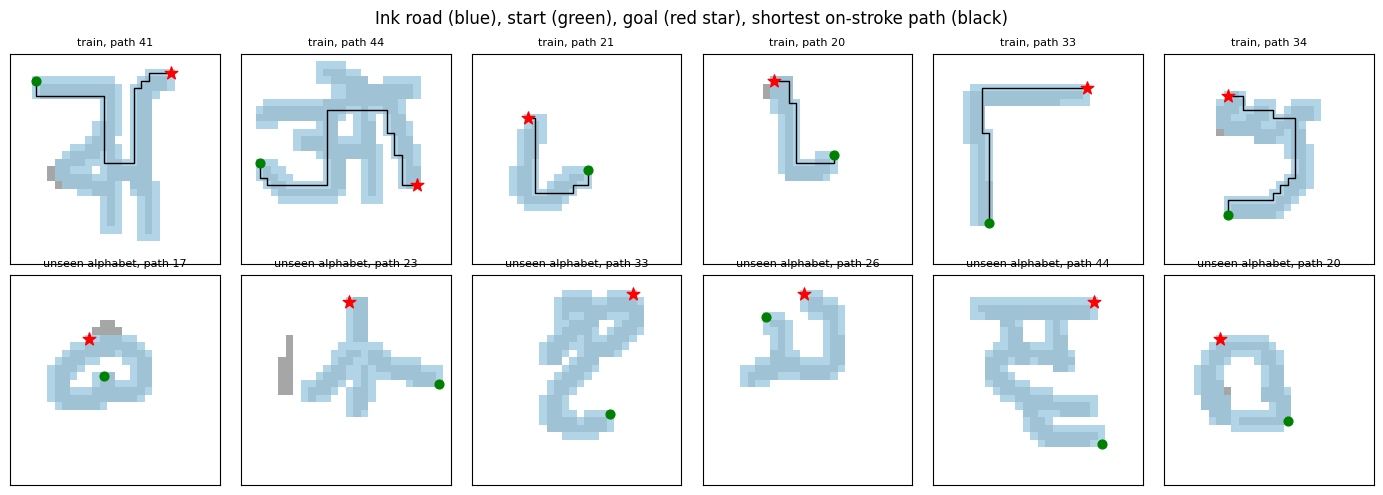

In [5]:
rng = np.random.default_rng(0)
train_tasks = make_tasks(train_imgs[rng.permutation(len(train_imgs))], CFG["min_len"], CFG["n_train_tasks"])
test_tasks = make_tasks(test_imgs[rng.permutation(len(test_imgs))], CFG["min_len"], CFG["n_test_tasks"])
seen_tasks = train_tasks[:CFG["n_eval_seen"]]
print(f"train tasks {len(train_tasks)} | unseen-alphabet test tasks {len(test_tasks)}")
print("path length (train): median", int(np.median([t["path_len"] for t in train_tasks])),
      "| max", max(t["path_len"] for t in train_tasks))

def shortest_path(task):
    # walk down dist_to_goal from the start
    D = np.where(np.isinf(task["dist_to_goal"]), 1e9, task["dist_to_goal"])
    p, path = task["start"], [task["start"]]
    while p != task["goal"]:
        p = min(((p[0] + dr, p[1] + dc) for dr, dc in DELTA
                 if 0 <= p[0] + dr < D.shape[0] and 0 <= p[1] + dc < D.shape[1]), key=lambda q: D[q])
        path.append(p)
    return np.array(path)

def show_task(ax, task, title=None):
    ax.imshow(task["img"], cmap="Greys", alpha=0.35)
    ax.imshow(np.ma.masked_where(~task["ink"], task["ink"]), cmap=ListedColormap(["#9ecae1"]), alpha=0.8)
    ax.scatter(task["start"][1], task["start"][0], c="green", s=40, zorder=3)
    ax.scatter(task["goal"][1], task["goal"][0], c="red", marker="*", s=90, zorder=3)
    ax.set_xticks([]); ax.set_yticks([])
    if title:
        ax.set_title(title, fontsize=8)

fig, axes = plt.subplots(2, 6, figsize=(14, 5))
for ax, t in zip(axes[0], train_tasks[:6]):
    show_task(ax, t, f"train, path {t['path_len']}")
    sp = shortest_path(t); ax.plot(sp[:, 1], sp[:, 0], c="k", lw=1)
for ax, t in zip(axes[1], test_tasks[:6]):
    show_task(ax, t, f"unseen alphabet, path {t['path_len']}")
plt.suptitle("Ink road (blue), start (green), goal (red star), shortest on-stroke path (black)")
plt.tight_layout(); plt.show()

## 3. The MDP and dynamic programming (one glyph)
States are the 28x28 = 784 pen positions. Entering a stroke cell costs 0.04, reaching the goal gives +10, and entering a paper cell gives -2 and ends the episode. Paper cells and the goal are terminal. The slip is part of the model: an intended action is executed as intended with probability 0.95 + 0.05/4, and as each other action with probability 0.05/4.

`GlyphMDP.q_from_v` is the Bellman backup. Value iteration repeats `V = max_a Q(V)`. Policy iteration alternates exact policy evaluation (a 784-variable linear solve) with greedy improvement. Iterative policy evaluation is also checked against the exact solve.

In [6]:
class GlyphMDP:
    # Exact model of one tracing task. States = all H*W pen positions.
    # Terminal states: the goal (success) and every paper cell (the pen left the stroke, failure).
    def __init__(self, task, slip, gamma, r_ink, r_paper, r_goal):
        ink = task["ink"]
        self.H, self.W = ink.shape
        self.S, self.A = self.H * self.W, 4
        self.gamma, self.slip = gamma, slip
        rr, cc = np.divmod(np.arange(self.S), self.W)
        self.nxt = np.zeros((self.S, 4), dtype=np.int64)
        for a in range(4):
            nr = np.clip(rr + DELTA[a, 0], 0, self.H - 1)
            nc = np.clip(cc + DELTA[a, 1], 0, self.W - 1)
            self.nxt[:, a] = nr * self.W + nc
        self.start = task["start"][0] * self.W + task["start"][1]
        self.goal = task["goal"][0] * self.W + task["goal"][1]
        self.r_enter = np.where(ink.ravel(), r_ink, r_paper).astype(float)    # reward for entering a cell
        self.r_enter[self.goal] = r_goal
        # T[a, b] = probability that intended action a is executed as b (pen slip)
        self.T = (1 - slip) * np.eye(4) + slip / 4.0
        self.terminal = ~ink.ravel().copy()
        self.terminal[self.goal] = True
        self.not_term_next = (~self.terminal[self.nxt]).astype(float)

    def q_from_v(self, V):
        executed = self.r_enter[self.nxt] + self.gamma * V[self.nxt] * self.not_term_next   # [S, b]
        Q = executed @ self.T.T                                                          # [S, a]
        Q[self.terminal] = 0.0
        return Q

    def value_iteration(self, theta=1e-8, max_iter=100_000):
        V = np.zeros(self.S)
        for it in range(1, max_iter + 1):
            V_new = self.q_from_v(V).max(1)
            delta = np.abs(V_new - V).max()
            V = V_new
            if delta < theta:
                return V, it
        return V, max_iter

    def policy_eval_exact(self, pi):
        # solve V = r_pi + gamma P_pi V with V = 0 on terminal states
        probs = self.T[pi]                                    # [S, b]
        P = np.zeros((self.S, self.S))
        np.add.at(P, (np.repeat(np.arange(self.S), 4), self.nxt.ravel()), probs.ravel())
        r = (probs * self.r_enter[self.nxt]).sum(1)
        P[self.terminal] = 0.0
        r[self.terminal] = 0.0
        P[:, self.terminal] = 0.0                             # entering a terminal state ends the episode
        return np.linalg.solve(np.eye(self.S) - self.gamma * P, r)

    def policy_eval_iterative(self, pi, theta=1e-8, max_iter=100_000):
        V = np.zeros(self.S)
        idx = np.arange(self.S)
        for it in range(1, max_iter + 1):
            V_new = self.q_from_v(V)[idx, pi]
            delta = np.abs(V_new - V).max()
            V = V_new
            if delta < theta:
                return V, it
        return V, max_iter

    def policy_iteration(self, max_iter=1000):
        pi = np.zeros(self.S, dtype=np.int64)
        idx = np.arange(self.S)
        for it in range(1, max_iter + 1):
            V = self.policy_eval_exact(pi)
            Q = self.q_from_v(V)
            new_pi = Q.argmax(1)
            if np.all(Q[idx, new_pi] - Q[idx, pi] <= 1e-10):
                return pi, V, it
            pi = new_pi
        return pi, V, max_iter

In [7]:
class TabularEnv:
    # Sampling interface to the same MDP, used by the model-free learners
    def __init__(self, mdp, horizon, rng):
        self.m, self.horizon, self.rng = mdp, horizon, rng

    def reset(self):
        self.s, self.t = self.m.start, 0
        return self.s

    def step(self, a):
        b = a if self.rng.random() >= self.m.slip else int(self.rng.integers(4))
        s2 = int(self.m.nxt[self.s, b])
        r = self.m.r_enter[s2]
        self.t += 1
        terminated = bool(self.m.terminal[s2])
        truncated = (not terminated) and self.t >= self.horizon
        self.s = s2
        return s2, r, terminated, truncated

def eps_greedy(Q, s, eps, rng):
    if rng.random() < eps:
        return int(rng.integers(Q.shape[1]))
    q = Q[s]
    return int(rng.choice(np.flatnonzero(q == q.max())))     # random tie-breaking

glyph path length 40 | 784 states
value iteration :   73 sweeps, 0.01s
policy iteration:   17 improvements, 0.34s
iterative policy evaluation of pi*: 73 sweeps, matches the exact solve
V*(start) = 4.403   |   value of the shortest-path policy = 2.722
success with 5% slips: optimal policy 94.1% | shortest-path policy 66.2%


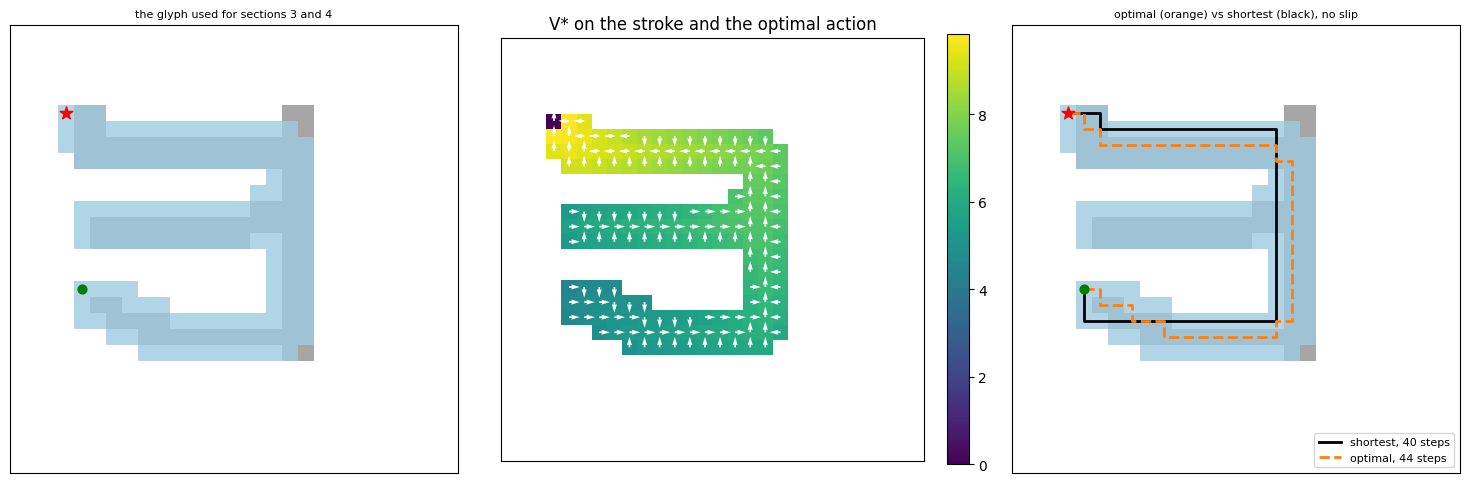

In [8]:
tab_task = min(train_tasks, key=lambda t: abs(t["path_len"] - CFG["tab_target_len"]))
mdp = GlyphMDP(tab_task, ENV["slip"], GAMMA, ENV["r_ink"], ENV["r_paper"], ENV["r_goal"])

t0 = time.time(); V_star, vi_iters = mdp.value_iteration(); t_vi = time.time() - t0
t0 = time.time(); pi_pi, V_pi, pi_iters = mdp.policy_iteration(); t_pi = time.time() - t0
pi_star = mdp.q_from_v(V_star).argmax(1)
V_iter, ev_iters = mdp.policy_eval_iterative(pi_star)
assert np.abs(V_star - V_pi).max() < 1e-5, "value iteration and policy iteration disagree"
assert np.abs(V_iter - mdp.policy_eval_exact(pi_star)).max() < 1e-5, "iterative and exact evaluation disagree"

# the shortest-path policy: always step to the neighbour closest to the goal along the stroke, ignoring slips
D = np.where(np.isinf(tab_task["dist_to_goal"]), 1e6, tab_task["dist_to_goal"]).ravel()
pi_short = D[mdp.nxt].argmin(1)
V_short = mdp.policy_eval_exact(pi_short)

print(f"glyph path length {tab_task['path_len']} | {mdp.S} states")
print(f"value iteration : {vi_iters:4d} sweeps, {t_vi:.2f}s")
print(f"policy iteration: {pi_iters:4d} improvements, {t_pi:.2f}s")
print(f"iterative policy evaluation of pi*: {ev_iters} sweeps, matches the exact solve")
print(f"V*(start) = {V_star[mdp.start]:.3f}   |   value of the shortest-path policy = {V_short[mdp.start]:.3f}")

def follow(pi, mdp, max_steps=500):
    s, path = mdp.start, [mdp.start]
    for _ in range(max_steps):
        if mdp.terminal[s]:
            break
        s = int(mdp.nxt[s, pi[s]]); path.append(s)
    return np.array(np.divmod(np.array(path), mdp.W)).T          # [L, 2] rows, cols

def success_rate(pi, mdp, horizon, n=1000, seed=0):
    env, wins = TabularEnv(mdp, horizon, np.random.default_rng(seed)), 0
    for _ in range(n):
        s, done = env.reset(), False
        while not done:
            s, _, term, trunc = env.step(int(pi[s])); done = term or trunc
        wins += s == mdp.goal
    return 100.0 * wins / n

H_tab = ENV["horizon_mult"] * tab_task["path_len"]
print(f"success with 5% slips: optimal policy {success_rate(pi_star, mdp, H_tab):.1f}% | shortest-path policy {success_rate(pi_short, mdp, H_tab):.1f}%")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
show_task(axes[0], tab_task, "the glyph used for sections 3 and 4")
Vm = np.ma.masked_where(~tab_task["ink"], V_star.reshape(mdp.H, mdp.W))
im = axes[1].imshow(Vm, cmap="viridis"); plt.colorbar(im, ax=axes[1], fraction=0.046)
rows, cols = np.nonzero(tab_task["ink"])
arrows = DELTA[pi_star.reshape(mdp.H, mdp.W)[rows, cols]]
axes[1].quiver(cols, rows, arrows[:, 1], -arrows[:, 0], scale=40, width=0.004, color="white")
axes[1].set_title("V* on the stroke and the optimal action"); axes[1].set_xticks([]); axes[1].set_yticks([])
show_task(axes[2], tab_task, "optimal (orange) vs shortest (black), no slip")
p1, p2 = follow(pi_star, mdp), follow(pi_short, mdp)
axes[2].plot(p2[:, 1], p2[:, 0], c="k", lw=2, label=f"shortest, {len(p2) - 1} steps")
axes[2].plot(p1[:, 1], p1[:, 0], c="tab:orange", lw=2, ls="--", label=f"optimal, {len(p1) - 1} steps")
axes[2].legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.savefig(f"{OUT}/dp_glyph.png", dpi=150, bbox_inches="tight"); plt.show()

## 4. Model-free control and planning (same glyph)
The learners only see sampled transitions. Each run gets the same budget of **real environment steps**; Dyna-Q's planning updates use its learned model and are not counted as interactions. After every 5,000 steps the current greedy policy is evaluated **exactly** with the DP solver, so the curves have no evaluation noise.

* **Monte Carlo** methods use exploring starts (a random stroke cell and a random first action), as in the course's Monte Carlo ES. Without them, a random walk almost never reaches a goal 40 steps away, and Monte Carlo has nothing to learn from.
* **TD methods and Dyna-Q** start from optimistic values (Q = 5), which makes even a greedy learner try every action. Their step size decays linearly from 0.1 to 0.01 over the run, which stops the greedy policy from flipping late in training.
* **Dyna-Q's model** keeps every observed outcome of each state-action pair and samples from them. The textbook version keeps only the last outcome, which is right for deterministic worlds; with slips it would sometimes remember a slip as the action's only result, and planning would keep repeating that mistake.
* Off-policy MC learns about the greedy policy while behaving epsilon-greedily, using weighted importance sampling (Sutton and Barto, Section 5.7).

In [9]:
def run_tabular(method, mdp, horizon, max_steps, seed, eps=0.1, alpha=0.1, n_plan=5, q_init=0.0, eval_every=5000):
    # runs until max_steps real environment interactions; planning updates (Dyna-Q) are not counted as interactions.
    # TD step size decays linearly from alpha to alpha/10, which damps late oscillations of the greedy policy.
    rng = np.random.default_rng(seed)
    env = TabularEnv(mdp, horizon, rng)
    Q = np.full((mdp.S, 4), float(q_init))   # optimistic values drive systematic exploration
    N = np.zeros((mdp.S, 4))            # visit counts (on-policy MC)
    C = np.zeros((mdp.S, 4))            # cumulative IS weights (off-policy MC)
    model, keys = {}, []                # Dyna-Q: (s, a) -> every observed (r, s2, terminated), plus the seen pairs
    g = mdp.gamma
    nonterminal = np.flatnonzero(~mdp.terminal)
    log, recent, steps, next_eval, ep = [], [], 0, 0, 0
    while steps < max_steps:
        ep += 1
        s, ep_ret, done = env.reset(), 0.0, False
        if method in ("mc_on", "mc_off"):
            # exploring starts: begin at a random stroke cell with a random first action (Monte Carlo ES)
            s = env.s = int(rng.choice(nonterminal))
            traj, first_action = [], int(rng.integers(4))
            while not done:
                if not traj:
                    a, b_prob = first_action, 0.25
                else:
                    a = eps_greedy(Q, s, eps, rng)
                    ties = Q[s] == Q[s].max()
                    b_prob = ((1 - eps) / ties.sum() if ties[a] else 0.0) + eps / 4.0
                s2, r, term, trunc = env.step(a)
                steps += 1
                traj.append((s, a, r, b_prob))
                ep_ret += r
                s, done = s2, term or trunc
            G, W = 0.0, 1.0
            if method == "mc_on":
                first = {}
                for t, (st, at, _, _) in enumerate(traj):
                    first.setdefault((st, at), t)
                for t in range(len(traj) - 1, -1, -1):
                    st, at, r, _ = traj[t]
                    G = g * G + r
                    if first[(st, at)] == t:                       # first-visit update, sample average
                        N[st, at] += 1
                        Q[st, at] += (G - Q[st, at]) / N[st, at]
            else:
                for t in range(len(traj) - 1, -1, -1):             # weighted importance sampling (Sutton & Barto 5.7)
                    st, at, r, b_prob = traj[t]
                    G = g * G + r
                    C[st, at] += W
                    Q[st, at] += W / C[st, at] * (G - Q[st, at])
                    if at != int(Q[st].argmax()):
                        break                                      # the greedy target policy would not take at
                    W /= b_prob
        else:
            a = eps_greedy(Q, s, eps, rng)
            while not done:
                lr = alpha * (1.0 - 0.9 * min(1.0, steps / max_steps))
                s2, r, term, trunc = env.step(a)
                steps += 1
                ep_ret += r
                a2 = eps_greedy(Q, s2, eps, rng)
                if method == "sarsa":
                    target = r + (0.0 if term else g * Q[s2, a2])
                else:                                              # q-learning and dyna-q
                    target = r + (0.0 if term else g * Q[s2].max())
                Q[s, a] += lr * (target - Q[s, a])
                if method == "dyna_q":
                    if (s, a) not in model:
                        keys.append((s, a))
                        model[(s, a)] = []
                    model[(s, a)].append((r, s2, term))    # sampling from all outcomes = the empirical slip model
                    for _ in range(n_plan):
                        ps, pa = keys[rng.integers(len(keys))]
                        outcomes = model[(ps, pa)]
                        pr, ps2, pterm = outcomes[rng.integers(len(outcomes))]
                        ptarget = pr + (0.0 if pterm else g * Q[ps2].max())
                        Q[ps, pa] += lr * (ptarget - Q[ps, pa])
                s, a, done = s2, a2, term or trunc
        recent.append(ep_ret)
        if steps >= next_eval or steps >= max_steps:
            pi = Q.argmax(1)
            log.append(dict(steps=steps, episode=ep, online_return=float(np.mean(recent)),
                            greedy_value=mdp.policy_eval_exact(pi)[mdp.start]))
            recent, next_eval = [], next_eval + eval_every
    return Q, log

In [10]:
# sanity check: on a short straight stroke both Monte Carlo methods must get close to the optimum
straight = np.zeros((28, 28), bool); straight[14, 5:21] = True
st_task = make_task(straight, min_len=5)
st_mdp = GlyphMDP(st_task, 0.0, GAMMA, ENV["r_ink"], ENV["r_paper"], ENV["r_goal"])
st_V, _ = st_mdp.value_iteration()
for m in ["mc_on", "mc_off"]:
    _, lg = run_tabular(m, st_mdp, 4 * st_task["path_len"], 60_000, 0, eps=CFG["tab_eps"], eval_every=20_000)
    print(f"{m}: greedy value {lg[-1]['greedy_value']:.3f} vs optimal {st_V[st_mdp.start]:.3f}")
    assert lg[-1]["greedy_value"] > 0.9 * st_V[st_mdp.start]
print("both Monte Carlo implementations get within 10% of the optimum on the straight stroke")

mc_on: greedy value 7.451 vs optimal 7.683
mc_off: greedy value 7.683 vs optimal 7.683
both Monte Carlo implementations get within 10% of the optimum on the straight stroke


In [11]:
TAB_METHODS = {"MC control, on-policy (ES)": "mc_on", "MC control, off-policy (weighted IS)": "mc_off",
               "Sarsa": "sarsa", "Q-learning": "q_learning", f"Dyna-Q ({CFG['tab_plan']} planning steps)": "dyna_q"}
grid = np.arange(0, CFG["tab_steps"] + 1, CFG["tab_eval_every"])
tab_curves, tab_final, tab_Q = {}, [], {}
for name, m in TAB_METHODS.items():
    t0 = time.time()
    curves = []
    for seed in CFG["tab_seeds"]:
        Q, log = run_tabular(m, mdp, H_tab, CFG["tab_steps"], seed, eps=CFG["tab_eps"], alpha=CFG["tab_alpha"],
                             n_plan=CFG["tab_plan"], q_init=0.0 if m.startswith("mc") else CFG["tab_q_init"],
                             eval_every=CFG["tab_eval_every"])
        lg = pd.DataFrame(log)
        curves.append(np.interp(grid, lg["steps"], lg["greedy_value"]))
        pi = Q.argmax(1)
        tab_final.append(dict(method=name, seed=seed, final_value=lg["greedy_value"].iloc[-3:].mean(),
                              success=success_rate(pi, mdp, H_tab, n=500, seed=seed)))
        tab_Q[(name, seed)] = Q
    tab_curves[name] = np.array(curves)
    print(f"{name:38s} done in {time.time() - t0:5.1f}s")

tab_df = pd.DataFrame(tab_final)
summary = tab_df.groupby("method", sort=False)[["final_value", "success"]].agg(["mean", "std"]).round(3)
display(summary)
print(f"optimal V*(start) = {V_star[mdp.start]:.3f} | shortest-path policy = {V_short[mdp.start]:.3f}")

MC control, on-policy (ES)             done in  32.8s
MC control, off-policy (weighted IS)   done in  32.2s
Sarsa                                  done in  24.9s
Q-learning                             done in  26.3s
Dyna-Q (5 planning steps)              done in  65.4s


final_value        success       
                                            mean    std    mean    std
method                                                                
MC control, on-policy (ES)                 3.164  0.171  78.067  4.438
MC control, off-policy (weighted IS)      -2.001  0.000   0.000  0.000
Sarsa                                      4.330  0.013  93.267  2.003
Q-learning                                 4.241  0.096  92.867  2.468
Dyna-Q (5 planning steps)                  4.354  0.027  93.000  0.721

optimal V*(start) = 4.403 | shortest-path policy = 2.722


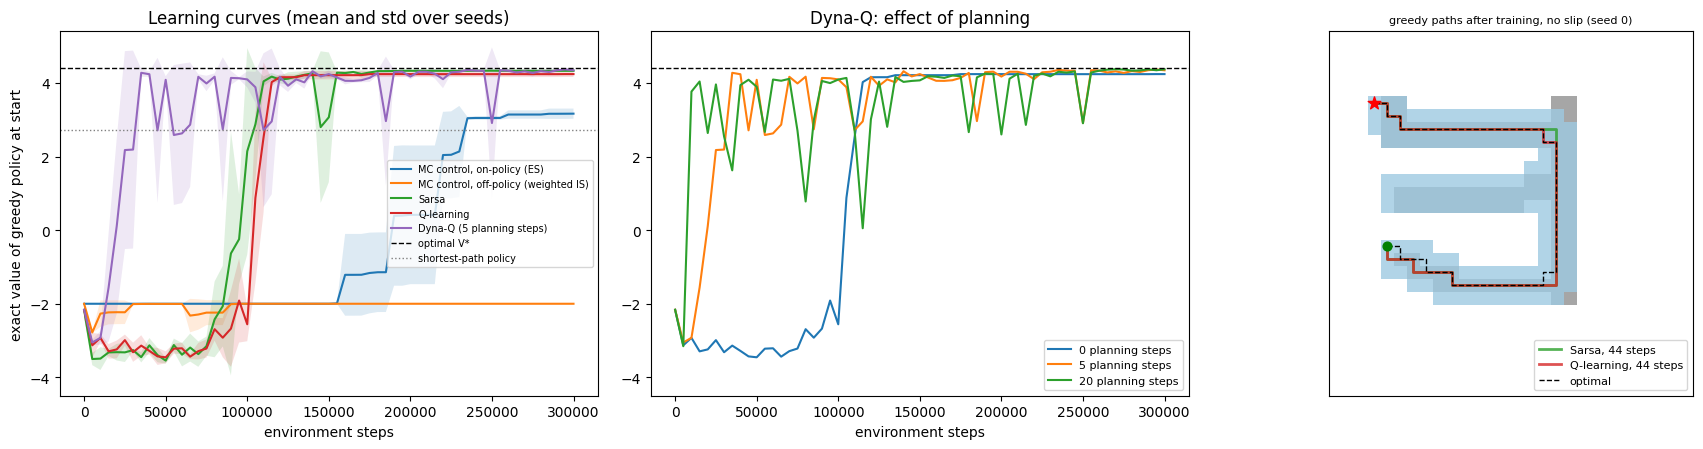

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.6))
for name, c in tab_curves.items():
    mu, sd = c.mean(0), c.std(0)
    axes[0].plot(grid, mu, label=name); axes[0].fill_between(grid, mu - sd, mu + sd, alpha=0.15)
axes[0].axhline(V_star[mdp.start], c="k", ls="--", lw=1, label="optimal V*")
axes[0].axhline(V_short[mdp.start], c="gray", ls=":", lw=1, label="shortest-path policy")
axes[0].set_ylim(-4.5, V_star[mdp.start] + 1)
axes[0].set_xlabel("environment steps"); axes[0].set_ylabel("exact value of greedy policy at start")
axes[0].set_title("Learning curves (mean and std over seeds)"); axes[0].legend(fontsize=7)

# planning: Dyna-Q with more planning steps per real step (0 planning steps = Q-learning)
for n_plan in CFG["dyna_sweep"]:
    curves = []
    for seed in CFG["tab_seeds"]:
        _, log = run_tabular("dyna_q", mdp, H_tab, CFG["tab_steps"], seed, eps=CFG["tab_eps"], alpha=CFG["tab_alpha"],
                             n_plan=n_plan, q_init=CFG["tab_q_init"], eval_every=CFG["tab_eval_every"])
        lg = pd.DataFrame(log)
        curves.append(np.interp(grid, lg["steps"], lg["greedy_value"]))
    axes[1].plot(grid, np.mean(curves, 0), label=f"{n_plan} planning steps")
axes[1].axhline(V_star[mdp.start], c="k", ls="--", lw=1)
axes[1].set_ylim(-4.5, V_star[mdp.start] + 1)
axes[1].set_xlabel("environment steps"); axes[1].set_title("Dyna-Q: effect of planning"); axes[1].legend(fontsize=8)

show_task(axes[2], tab_task, "greedy paths after training, no slip (seed 0)")
for name, col in [("Sarsa", "tab:green"), ("Q-learning", "tab:red")]:
    p = follow(tab_Q[(name, CFG["tab_seeds"][0])].argmax(1), mdp)
    axes[2].plot(p[:, 1], p[:, 0], c=col, lw=2, alpha=0.8, label=f"{name}, {len(p) - 1} steps")
p = follow(pi_star, mdp)
axes[2].plot(p[:, 1], p[:, 0], c="k", lw=1, ls="--", label="optimal")
axes[2].legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.savefig(f"{OUT}/tabular.png", dpi=150, bbox_inches="tight"); plt.show()

### What to look for in sections 3 and 4
* **Safe beats short.** The optimal policy has a higher value and success rate than the shortest-path policy even though it takes more steps, because it keeps away from the stroke edges where a slip is fatal. Dynamic programming finds this only because the slip is in the model.
* **Sarsa versus Q-learning.** Sarsa learns the value of the epsilon-greedy policy it actually runs, so it tends to settle on safer paths and smoother curves. Q-learning learns the greedy optimum directly, and its greedy policy can switch back and forth as estimates move. The sudden drops in its curve are such switches: one wrong arrow can trap the exact evaluation in a loop.
* **Off-policy Monte Carlo is slow here, and the sanity check shows this is not a bug.** It reaches the optimum on a straight stroke, but weighted importance sampling only learns from the part of each episode after the last exploratory action. On a 40-step curved stroke those greedy tails rarely reach back to the start within the budget. This is the variance problem of importance sampling discussed in the course.
* **Planning trades computation for data.** Dyna-Q with planning steps reaches good policies in far fewer real steps than plain Q-learning (0 planning steps), at the cost of more updates per step.

## 5. Many glyphs: the vectorized environment and reference policies
A tabular agent learns one glyph and knows nothing about the next. To trace characters it has never seen, an agent must work from what it can observe: an 11x11 window around the pen showing the stroke and the cells it has already visited, plus the direction to the goal. It never sees the whole map.

Reference policies:
* **Random** and **compass** (move straight towards the goal, ignoring the stroke): lower bounds.
* **Shortest path** and **DP optimal**: both see the full map; the second also plans for slips. These are upper references, not competitors.

In [13]:
_TASK_BANKS = {}

class VecGlyphEnv:
    # n parallel tracing tasks. Observation = egocentric crop of (ink, visited) around the pen + goal offset.
    # autoreset=True: a finished env immediately starts a new random task (training).
    # autoreset=False: env i runs task_ids[i] once and then stays frozen (evaluation, episode batches).
    def __init__(self, tasks, n, cfg, seed, autoreset=True, task_ids=None):
        self.cfg, self.n, self.autoreset = cfg, n, autoreset
        self.rng = np.random.default_rng(seed)
        self.p = cfg["crop"] // 2
        H, W = tasks[0]["ink"].shape
        self.H, self.W = H, W
        key = (id(tasks), len(tasks), self.p)            # stacked task arrays are built once per task list
        if key not in _TASK_BANKS:
            ink = np.stack([t["ink"] for t in tasks])
            _TASK_BANKS[key] = (ink, np.pad(ink, ((0, 0), (self.p, self.p), (self.p, self.p))),
                                np.array([t["start"] for t in tasks]), np.array([t["goal"] for t in tasks]),
                                np.array([t["path_len"] for t in tasks]))
        self.INK, self.INKP, self.START, self.GOAL, self.PLEN = _TASK_BANKS[key]
        self.off = np.arange(-self.p, self.p + 1)
        self.fixed = None if task_ids is None else np.asarray(task_ids)
        self.tid = np.zeros(n, dtype=np.int64)
        self.pos = np.zeros((n, 2), dtype=np.int64)
        self.t = np.zeros(n, dtype=np.int64)
        self.visited = np.zeros((n, H + 2 * self.p, W + 2 * self.p), dtype=np.float32)
        self.active = np.ones(n, dtype=bool)
        self.ep_ret = np.zeros(n)
        self.ep_off = np.zeros(n, dtype=np.int64)
        self.finished = []                                   # stats of completed episodes
        self._reset(np.arange(n))

    @property
    def obs_dim(self):
        return 2 * self.cfg["crop"] ** 2 + 2

    def _reset(self, idx):
        if len(idx) == 0:
            return
        self.tid[idx] = self.fixed[idx] if self.fixed is not None else self.rng.integers(len(self.INK), size=len(idx))
        self.pos[idx] = self.START[self.tid[idx]]
        self.t[idx] = 0
        self.visited[idx] = 0.0
        self.visited[idx, self.pos[idx, 0] + self.p, self.pos[idx, 1] + self.p] = 1.0
        self.ep_ret[idx] = 0.0
        self.ep_off[idx] = 0

    def horizon(self):
        return self.cfg["horizon_mult"] * self.PLEN[self.tid]

    def obs(self):
        rows = (self.pos[:, 0] + self.p)[:, None] + self.off[None]          # [n, k]
        cols = (self.pos[:, 1] + self.p)[:, None] + self.off[None]
        ink = self.INKP[self.tid[:, None, None], rows[:, :, None], cols[:, None, :]].astype(np.float32)
        vis = self.visited[np.arange(self.n)[:, None, None], rows[:, :, None], cols[:, None, :]]
        goal = (self.GOAL[self.tid] - self.pos).astype(np.float32) / max(self.H, self.W)
        return np.concatenate([ink.reshape(self.n, -1), vis.reshape(self.n, -1), goal], axis=1)

    def step(self, actions):
        cfg = self.cfg
        a = np.asarray(actions).copy()
        slip = self.rng.random(self.n) < cfg["slip"]
        a[slip] = self.rng.integers(4, size=int(slip.sum()))
        new = np.clip(self.pos + DELTA[a], 0, [self.H - 1, self.W - 1])
        on_ink = self.INK[self.tid, new[:, 0], new[:, 1]]
        at_goal = np.all(new == self.GOAL[self.tid], axis=1)
        r = np.where(at_goal, cfg["r_goal"], np.where(on_ink, cfg["r_ink"], cfg["r_paper"])).astype(np.float32)
        act = self.active
        r = np.where(act, r, 0.0).astype(np.float32)
        self.pos[act] = new[act]
        self.t[act] += 1
        self.visited[np.flatnonzero(act), self.pos[act, 0] + self.p, self.pos[act, 1] + self.p] = 1.0
        self.ep_ret[act] += r[act]
        self.ep_off[act] += (~on_ink[act]).astype(np.int64)
        terminated = act & (at_goal | ~on_ink)               # goal reached, or the pen left the stroke
        truncated = act & ~terminated & (self.t >= self.horizon())
        final_obs = self.obs()                                # observation before any reset (for bootstrapping)
        ended = np.flatnonzero(terminated | truncated)
        for i in ended:
            self.finished.append(dict(task=int(self.tid[i]), success=bool(at_goal[i]), steps=int(self.t[i]),
                                      ret=float(self.ep_ret[i]), off_ink=int(self.ep_off[i]),
                                      opt=int(self.PLEN[self.tid[i]])))
        if self.autoreset:
            self._reset(ended)
        else:
            self.active[ended] = False
        return self.obs(), r, terminated, truncated, final_obs

    def pop_stats(self):
        out, self.finished = self.finished, []
        return out

In [14]:
def random_policy(env):
    return env.rng.integers(4, size=env.n)

def compass_policy(env):
    # move along the larger goal offset, ignoring the stroke (a "straight line" baseline)
    d = env.GOAL[env.tid] - env.pos
    vert = np.where(d[:, 0] < 0, 0, 1)
    horz = np.where(d[:, 1] < 0, 2, 3)
    return np.where(np.abs(d[:, 0]) >= np.abs(d[:, 1]), vert, horz)

def make_oracle(tasks):
    # follows the shortest on-stroke path using the full map, which the agents never see; re-plans after slips.
    # Shortest is not safest: it cuts corners, so a slip there can push the pen off the stroke.
    D = np.stack([np.where(np.isinf(t["dist_to_goal"]), 1e6, t["dist_to_goal"]) for t in tasks])
    def policy(env):
        best = np.zeros(env.n, dtype=np.int64)
        best_d = np.full(env.n, np.inf)
        for a in range(4):
            nxt = np.clip(env.pos + DELTA[a], 0, [env.H - 1, env.W - 1])
            d = D[env.tid, nxt[:, 0], nxt[:, 1]]
            better = d < best_d
            best[better], best_d[better] = a, d[better]
        return best
    return policy

def run_episodes(policy_fn, tasks, cfg, seed, task_ids=None):
    # every task in task_ids is run once; returns per-episode stats
    ids = np.arange(len(tasks)) if task_ids is None else np.asarray(task_ids)
    env = VecGlyphEnv(tasks, len(ids), cfg, seed, autoreset=False, task_ids=ids)
    while env.active.any():
        env.step(policy_fn(env))
    return env.pop_stats()

def summarize(stats):
    s = np.array([x["success"] for x in stats], dtype=float)
    steps = np.array([x["steps"] for x in stats], dtype=float)
    opt = np.array([x["opt"] for x in stats], dtype=float)
    spl = s * opt / np.maximum(opt, steps)                   # success weighted by path length (Anderson et al., 2018)
    return dict(success=100 * s.mean(), spl=100 * spl.mean(),
                off_ink=np.mean([x["off_ink"] for x in stats]), ret=np.mean([x["ret"] for x in stats]))

def make_dp_optimal(tasks, cfg, gamma):
    # per-task optimal policy from value iteration on the full map: the best any agent could do on reward
    pis = []
    for t in tasks:
        m = GlyphMDP(t, cfg["slip"], gamma, cfg["r_ink"], cfg["r_paper"], cfg["r_goal"])
        V, _ = m.value_iteration(theta=1e-6)
        pis.append(m.q_from_v(V).argmax(1))
    PI = np.stack(pis)
    def policy(env):
        return PI[env.tid, env.pos[:, 0] * env.W + env.pos[:, 1]]
    return policy

In [15]:
env_check = VecGlyphEnv(train_tasks, 8, ENV, 0)
o = env_check.obs()
k, c = ENV["crop"], ENV["crop"] // 2
assert o.shape == (8, env_check.obs_dim) and np.all(o[:, c * k + c] == 1.0), "pen must start on the stroke"
t0, n = time.time(), 0
for _ in range(500):
    env_check.step(random_policy(env_check)); n += 8
print(f"observation size {env_check.obs_dim} | {n / (time.time() - t0):,.0f} environment steps per second")
nos = summarize(run_episodes(make_oracle(test_tasks), test_tasks, dict(ENV, slip=0.0), 1))
assert nos["success"] == 100.0, "without slips the shortest-path planner must always succeed"

t0 = time.time()
dp_seen, dp_test = make_dp_optimal(seen_tasks, ENV, GAMMA), make_dp_optimal(test_tasks, ENV, GAMMA)
print(f"DP-optimal policies for {len(seen_tasks) + len(test_tasks)} glyphs in {time.time() - t0:.1f}s")

REFERENCE = {"Random": (random_policy, random_policy), "Compass": (compass_policy, compass_policy),
             "Shortest path (full map)": (make_oracle(seen_tasks), make_oracle(test_tasks)),
             "DP optimal (full map)": (dp_seen, dp_test)}
deep_rows = []
for name, (p_seen, p_test) in REFERENCE.items():
    for split, tasks, pol in [("seen", seen_tasks, p_seen), ("unseen", test_tasks, p_test)]:
        deep_rows.append(dict(method=name, split=split, **summarize(run_episodes(pol, tasks, ENV, seed=123))))
display(pd.DataFrame(deep_rows).round(2))

observation size 244 | 28,956 environment steps per second
DP-optimal policies for 1000 glyphs in 5.4s


,method,split,success,spl,off_ink,ret
0,Random,seen,0.0,0.00,1.00,-2.11
1,Random,unseen,0.0,0.00,1.00,-2.12
2,Compass,seen,2.6,2.57,0.97,-1.86
3,Compass,unseen,4.4,4.27,0.96,-1.67
4,Shortest path (full map),seen,69.6,66.70,0.30,5.26
5,Shortest path (full map),unseen,75.4,72.64,0.25,5.98
6,DP optimal (full map),seen,94.0,86.89,0.06,7.96
7,DP optimal (full map),unseen,95.0,88.12,0.05,8.12


## 6. Function approximation and deep RL
All learners share the same observation and the same two-layer MLP size, and are evaluated with their greedy action on identical episodes (same glyphs, same slip noise).

* **Behaviour cloning** (supervised learning refresher): imitates the DP planner's actions. It uses a privileged teacher, so it shows what the observation can support rather than what RL discovers on its own.
* **DQN** (Mnih et al., 2015): semi-gradient Q-learning with an experience replay buffer, a target network and a Huber loss.
* **REINFORCE with baseline** (Williams, 1992): Monte Carlo policy gradient on batches of complete episodes, with a learned value baseline.
* **A2C**: synchronous advantage actor-critic with n-step returns from parallel environments.
* **PPO** (Schulman et al., 2017): clipped surrogate objective, generalized advantage estimation, several epochs per batch.

Time limits are handled as truncation, not termination: when an episode is cut by the horizon, the value targets bootstrap from the true next state.

In [16]:
# [torch] deep RL setup
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.distributions import Categorical

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"torch {torch.__version__} | device: {DEVICE}")
OBS_DIM = 2 * ENV["crop"] ** 2 + 2

def seed_all(seed):
    set_seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

def to_t(x):
    return torch.as_tensor(x, dtype=torch.float32, device=DEVICE)

def mlp(inp, out, hidden=256):
    return nn.Sequential(nn.Linear(inp, hidden), nn.ReLU(), nn.Linear(hidden, hidden), nn.ReLU(), nn.Linear(hidden, out))

def greedy_policy(net):
    def policy(env):
        with torch.no_grad():
            return net(to_t(env.obs())).argmax(1).cpu().numpy()
    return policy

class CurveLogger:
    def __init__(self):
        self.rows = []
    def add(self, steps, stats):
        if stats:
            self.rows.append(dict(steps=steps, episodes=len(stats), **summarize(stats)))
    def df(self):
        return pd.DataFrame(self.rows)

# quick checks
net = mlp(OBS_DIM, 4).to(DEVICE)
e = VecGlyphEnv(train_tasks, 4, ENV, 0)
assert net(to_t(e.obs())).shape == (4, 4) and greedy_policy(net)(e).shape == (4,)
print("deep setup ok")

torch 2.11.0+cu130 | device: cuda
deep setup ok


In [17]:
# [torch] behaviour cloning of the DP planner
def train_bc(tasks, cfg, seed):
    seed_all(seed)
    expert = make_dp_optimal(tasks, ENV, GAMMA)
    X, Y = [], []
    for rep in range(cfg["bc_rollouts"]):
        env = VecGlyphEnv(tasks, len(tasks), ENV, seed + rep, autoreset=False, task_ids=np.arange(len(tasks)))
        while env.active.any():
            o, a = env.obs(), expert(env)
            X.append(o[env.active]); Y.append(a[env.active])
            env.step(a)
    X, Y = to_t(np.concatenate(X)), torch.as_tensor(np.concatenate(Y), device=DEVICE)
    net = mlp(OBS_DIM, 4).to(DEVICE)
    opt = torch.optim.Adam(net.parameters(), lr=1e-3)
    for _ in range(cfg["bc_epochs"]):
        perm = torch.randperm(len(X), device=DEVICE)
        for i in range(0, len(X), 512):
            idx = perm[i:i + 512]
            loss = F.cross_entropy(net(X[idx]), Y[idx])
            opt.zero_grad(); loss.backward(); opt.step()
    with torch.no_grad():
        acc = (net(X).argmax(1) == Y).float().mean().item()
    print(f"  behaviour cloning: {len(X):,} expert samples, training accuracy {acc:.3f}")
    return net

t0 = time.time()
bc_net = train_bc(train_tasks, CFG, CFG["deep_seed"])
print(f"  done in {time.time() - t0:.0f}s")

  behaviour cloning: 188,360 expert samples, training accuracy 0.995
  done in 22s


In [18]:
# [torch] DQN
def train_dqn(tasks, cfg, seed):
    seed_all(seed)
    rng = np.random.default_rng(seed)
    env = VecGlyphEnv(tasks, cfg["dqn_envs"], ENV, seed)
    n, cap = env.n, cfg["dqn_buffer"]
    q = mlp(OBS_DIM, 4).to(DEVICE)
    q_target = copy.deepcopy(q)
    opt = torch.optim.Adam(q.parameters(), lr=cfg["dqn_lr"])
    B_o, B_o2 = np.zeros((cap, OBS_DIM), np.float32), np.zeros((cap, OBS_DIM), np.float32)
    B_a, B_r, B_d = np.zeros(cap, np.int64), np.zeros(cap, np.float32), np.zeros(cap, np.float32)
    ptr = size = steps = updates = 0
    log, next_log, total = CurveLogger(), cfg["log_every"], cfg["dqn_steps"]
    o = env.obs()
    while steps < total:
        eps = max(cfg["dqn_eps_end"], 1.0 - steps / (cfg["dqn_eps_frac"] * total))
        with torch.no_grad():
            greedy = q(to_t(o)).argmax(1).cpu().numpy()
        a = np.where(rng.random(n) < eps, rng.integers(4, size=n), greedy)
        o2, r, term, trunc, final_obs = env.step(a)
        idx = (ptr + np.arange(n)) % cap
        B_o[idx], B_a[idx], B_r[idx], B_o2[idx], B_d[idx] = o, a, r, final_obs, term   # truncation is not terminal
        ptr, size, steps, o = (ptr + n) % cap, min(size + n, cap), steps + n, o2
        if size >= cfg["dqn_learn_start"]:
            for _ in range(cfg["dqn_updates_per_iter"]):
                j = rng.integers(size, size=cfg["dqn_batch"])
                ob, o2b = to_t(B_o[j]), to_t(B_o2[j])
                ab = torch.as_tensor(B_a[j], device=DEVICE)
                with torch.no_grad():
                    target = to_t(B_r[j]) + GAMMA * (1.0 - to_t(B_d[j])) * q_target(o2b).max(1).values
                loss = F.smooth_l1_loss(q(ob).gather(1, ab[:, None]).squeeze(1), target)
                opt.zero_grad(); loss.backward()
                nn.utils.clip_grad_norm_(q.parameters(), 10.0); opt.step()
                updates += 1
                if updates % cfg["dqn_target_every"] == 0:
                    q_target.load_state_dict(q.state_dict())
        if steps >= next_log:
            log.add(steps, env.pop_stats()); next_log += cfg["log_every"]
    return q, log.df()

t0 = time.time()
dqn_net, dqn_curve = train_dqn(train_tasks, CFG, CFG["deep_seed"])
print(f"DQN done in {time.time() - t0:.0f}s")

DQN done in 180s


In [19]:
# [torch] REINFORCE with a learned baseline
def train_reinforce(tasks, cfg, seed):
    seed_all(seed)
    rng = np.random.default_rng(seed)
    pi, v = mlp(OBS_DIM, 4).to(DEVICE), mlp(OBS_DIM, 1).to(DEVICE)
    opt = torch.optim.Adam(list(pi.parameters()) + list(v.parameters()), lr=cfg["pg_lr"])
    steps, log = 0, CurveLogger()
    while steps < cfg["pg_steps"]:
        ids = rng.integers(len(tasks), size=cfg["pg_batch_episodes"])
        env = VecGlyphEnv(tasks, len(ids), ENV, int(rng.integers(2**31)), autoreset=False, task_ids=ids)
        O, A, R, M = [], [], [], []
        o = env.obs()
        while env.active.any():
            alive = env.active.copy()
            with torch.no_grad():
                a = Categorical(logits=pi(to_t(o))).sample().cpu().numpy()
            o2, r, _, _, _ = env.step(a)
            O.append(o); A.append(a); R.append(r); M.append(alive)
            o = o2
        R, M = np.stack(R), np.stack(M)                       # [T, n]
        G, run = np.zeros_like(R), np.zeros(R.shape[1], np.float32)
        for t in range(len(R) - 1, -1, -1):                   # rewards after an episode ends are 0
            run = R[t] + GAMMA * run
            G[t] = run
        mask = M.reshape(-1)
        obs = to_t(np.stack(O).reshape(-1, OBS_DIM)[mask])
        act = torch.as_tensor(np.stack(A).reshape(-1)[mask], device=DEVICE)
        ret = to_t(G.reshape(-1)[mask])
        dist = Categorical(logits=pi(obs))
        val = v(obs).squeeze(1)
        loss = (-(dist.log_prob(act) * (ret - val).detach()).mean() + 0.5 * F.mse_loss(val, ret)
                - cfg["ent_coef"] * dist.entropy().mean())
        opt.zero_grad(); loss.backward()
        nn.utils.clip_grad_norm_(list(pi.parameters()) + list(v.parameters()), 1.0); opt.step()
        steps += int(mask.sum())
        log.add(steps, env.pop_stats())
    return pi, log.df()

t0 = time.time()
reinforce_net, reinforce_curve = train_reinforce(train_tasks, CFG, CFG["deep_seed"])
print(f"REINFORCE done in {time.time() - t0:.0f}s")

REINFORCE done in 129s


In [20]:
# [torch] A2C and PPO share the rollout and advantage code
class ActorCritic(nn.Module):
    def __init__(self):
        super().__init__()
        self.pi, self.v = mlp(OBS_DIM, 4), mlp(OBS_DIM, 1)
    def forward(self, x):
        return self.pi(x), self.v(x).squeeze(-1)

def collect_rollout(env, ac, o, T):
    n = env.n
    B = dict(O=np.zeros((T, n, OBS_DIM), np.float32), A=np.zeros((T, n), np.int64), LP=np.zeros((T, n), np.float32),
             R=np.zeros((T, n), np.float32), V=np.zeros((T, n), np.float32), TERM=np.zeros((T, n), np.float32),
             TRUNC=np.zeros((T, n), np.float32), BOOT=np.zeros((T, n), np.float32))
    for t in range(T):
        with torch.no_grad():
            logits, val = ac(to_t(o))
            dist = Categorical(logits=logits)
            a = dist.sample()
        B["O"][t], B["A"][t] = o, a.cpu().numpy()
        B["LP"][t], B["V"][t] = dist.log_prob(a).cpu().numpy(), val.cpu().numpy()
        o2, r, term, trunc, final_obs = env.step(B["A"][t])
        B["R"][t], B["TERM"][t], B["TRUNC"][t] = r, term, trunc
        if trunc.any():                                        # bootstrap from the real next state at a time limit
            with torch.no_grad():
                B["BOOT"][t, trunc] = ac(to_t(final_obs[trunc]))[1].cpu().numpy()
        o = o2
    with torch.no_grad():
        B["last_v"] = ac(to_t(o))[1].cpu().numpy()
    return B, o

def advantages(B, gamma, lam):
    T = B["R"].shape[0]
    adv, last = np.zeros_like(B["R"]), np.zeros(B["R"].shape[1], np.float32)
    for t in range(T - 1, -1, -1):
        next_v = B["last_v"] if t == T - 1 else B["V"][t + 1]
        ended = np.maximum(B["TERM"][t], B["TRUNC"][t])
        next_value = (1.0 - ended) * next_v + B["TRUNC"][t] * B["BOOT"][t]
        delta = B["R"][t] + gamma * next_value - B["V"][t]
        last = delta + gamma * lam * (1.0 - ended) * last
        adv[t] = last
    return adv, adv + B["V"]

def train_actor_critic(kind, tasks, cfg, seed):
    seed_all(seed)
    env = VecGlyphEnv(tasks, cfg["ac_envs"], ENV, seed)
    ac = ActorCritic().to(DEVICE)
    lr, T, lam = (cfg["a2c_lr"], cfg["a2c_rollout"], 1.0) if kind == "a2c" else (cfg["ppo_lr"], cfg["ppo_rollout"], 0.95)
    opt = torch.optim.Adam(ac.parameters(), lr=lr, eps=1e-5)
    o, steps, log, next_log = env.obs(), 0, CurveLogger(), cfg["log_every"]
    while steps < cfg["ac_steps"]:
        B, o = collect_rollout(env, ac, o, T)
        steps += T * env.n
        adv, ret = advantages(B, GAMMA, lam)
        O = to_t(B["O"].reshape(-1, OBS_DIM))
        A = torch.as_tensor(B["A"].reshape(-1), device=DEVICE)
        LP_old, ADV, RET = to_t(B["LP"].reshape(-1)), to_t(adv.reshape(-1)), to_t(ret.reshape(-1))
        if kind == "a2c":
            logits, v = ac(O)
            dist = Categorical(logits=logits)
            loss = -(dist.log_prob(A) * ADV).mean() + 0.5 * F.mse_loss(v, RET) - cfg["ent_coef"] * dist.entropy().mean()
            opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(ac.parameters(), 0.5); opt.step()
        else:
            N = len(A)
            mb = N // cfg["ppo_minibatches"]
            for _ in range(cfg["ppo_epochs"]):
                perm = torch.randperm(N, device=DEVICE)
                for i in range(0, N, mb):
                    idx = perm[i:i + mb]
                    logits, v = ac(O[idx])
                    dist = Categorical(logits=logits)
                    ratio = (dist.log_prob(A[idx]) - LP_old[idx]).exp()
                    a_mb = (ADV[idx] - ADV[idx].mean()) / (ADV[idx].std() + 1e-8)
                    pg = -torch.min(ratio * a_mb, ratio.clamp(1 - cfg["ppo_clip"], 1 + cfg["ppo_clip"]) * a_mb).mean()
                    loss = pg + 0.5 * F.mse_loss(v, RET[idx]) - cfg["ent_coef"] * dist.entropy().mean()
                    opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(ac.parameters(), 0.5); opt.step()
        if steps >= next_log:
            log.add(steps, env.pop_stats()); next_log += cfg["log_every"]
    return ac, log.df()

t0 = time.time(); a2c_net, a2c_curve = train_actor_critic("a2c", train_tasks, CFG, CFG["deep_seed"])
print(f"A2C done in {time.time() - t0:.0f}s")
t0 = time.time(); ppo_net, ppo_curve = train_actor_critic("ppo", train_tasks, CFG, CFG["deep_seed"])
print(f"PPO done in {time.time() - t0:.0f}s")

A2C done in 63s
PPO done in 72s


## 7. Results on seen and unseen alphabets
**Success** = reached the goal without leaving the stroke. **SPL** = success weighted by optimal path length over steps taken (Anderson et al., 2018), so wandering is penalized. **Return** is the undiscounted sum of rewards in the episode.

In [21]:
# [torch] evaluation of the learned policies on identical episodes
LEARNED = {"Behaviour cloning (DP teacher)": greedy_policy(bc_net), "DQN": greedy_policy(dqn_net),
           "REINFORCE + baseline": greedy_policy(reinforce_net),
           "A2C": greedy_policy(lambda x: a2c_net(x)[0]), "PPO": greedy_policy(lambda x: ppo_net(x)[0])}
for name, pol in LEARNED.items():
    for split, tasks in [("seen", seen_tasks), ("unseen", test_tasks)]:
        deep_rows.append(dict(method=name, split=split, **summarize(run_episodes(pol, tasks, ENV, seed=123))))

res = pd.DataFrame(deep_rows)
res.to_csv(f"{OUT}/deep_results.csv", index=False)
table = res.pivot_table(index="method", columns="split", values=["success", "spl", "ret"], aggfunc="first")
table = table.reindex(list(REFERENCE) + list(LEARNED))
display(table.round(1))

ret          spl        success       
split                          seen unseen  seen unseen    seen unseen
method                                                                
Random                         -2.1   -2.1   0.0    0.0     0.0    0.0
Compass                        -1.9   -1.7   2.6    4.3     2.6    4.4
Shortest path (full map)        5.3    6.0  66.7   72.6    69.6   75.4
DP optimal (full map)           8.0    8.1  86.9   88.1    94.0   95.0
Behaviour cloning (DP teacher)  6.5    4.6  75.4   60.3    81.4   65.8
DQN                            -2.9   -3.1   5.1    3.6     6.6    4.6
REINFORCE + baseline           -2.0   -2.0   0.0    0.0     0.0    0.0
A2C                            -2.0   -2.0   0.0    0.0     0.0    0.0
PPO                            -2.0   -2.0   0.0    0.0     0.0    0.0

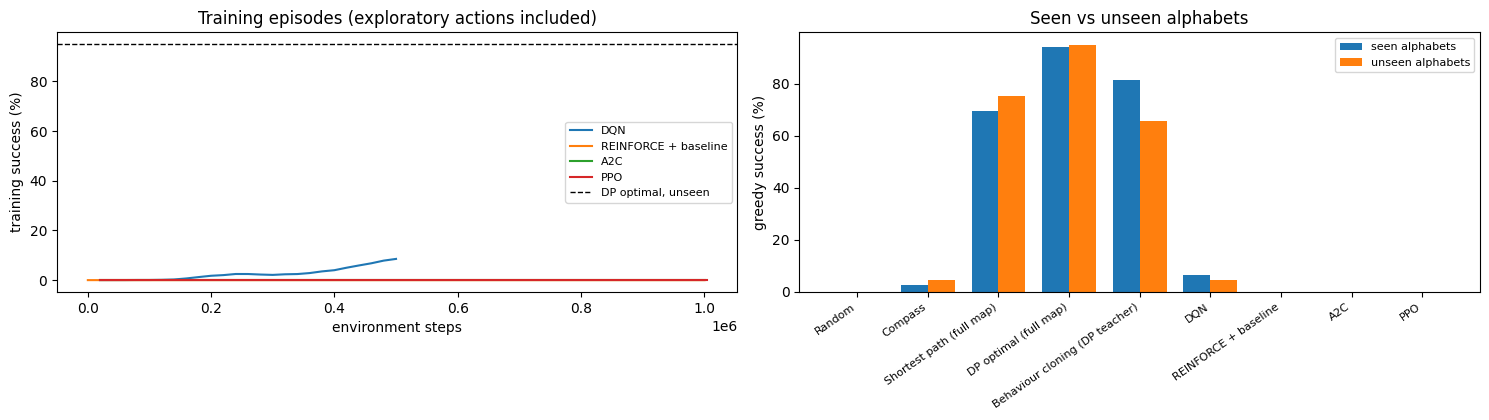

In [22]:
# [torch] learning curves and generalization gap
fig, axes = plt.subplots(1, 2, figsize=(15, 4.3))
for name, curve in [("DQN", dqn_curve), ("REINFORCE + baseline", reinforce_curve), ("A2C", a2c_curve), ("PPO", ppo_curve)]:
    if len(curve):
        axes[0].plot(curve["steps"], curve["success"].rolling(5, min_periods=1).mean(), label=name)
dp_unseen = res[(res.method == "DP optimal (full map)") & (res.split == "unseen")]["success"].item()
axes[0].axhline(dp_unseen, c="k", ls="--", lw=1, label="DP optimal, unseen")
axes[0].set_xlabel("environment steps"); axes[0].set_ylabel("training success (%)"); axes[0].legend(fontsize=8)
axes[0].set_title("Training episodes (exploratory actions included)")

order = list(REFERENCE) + list(LEARNED)
x = np.arange(len(order))
for i, split in enumerate(["seen", "unseen"]):
    vals = res[res.split == split].set_index("method").reindex(order)["success"]
    axes[1].bar(x + (i - 0.5) * 0.38, vals, 0.38, label=f"{split} alphabets")
axes[1].set_xticks(x); axes[1].set_xticklabels(order, rotation=35, ha="right", fontsize=8)
axes[1].set_ylabel("greedy success (%)"); axes[1].set_title("Seen vs unseen alphabets"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig(f"{OUT}/deep_results.png", dpi=150, bbox_inches="tight"); plt.show()

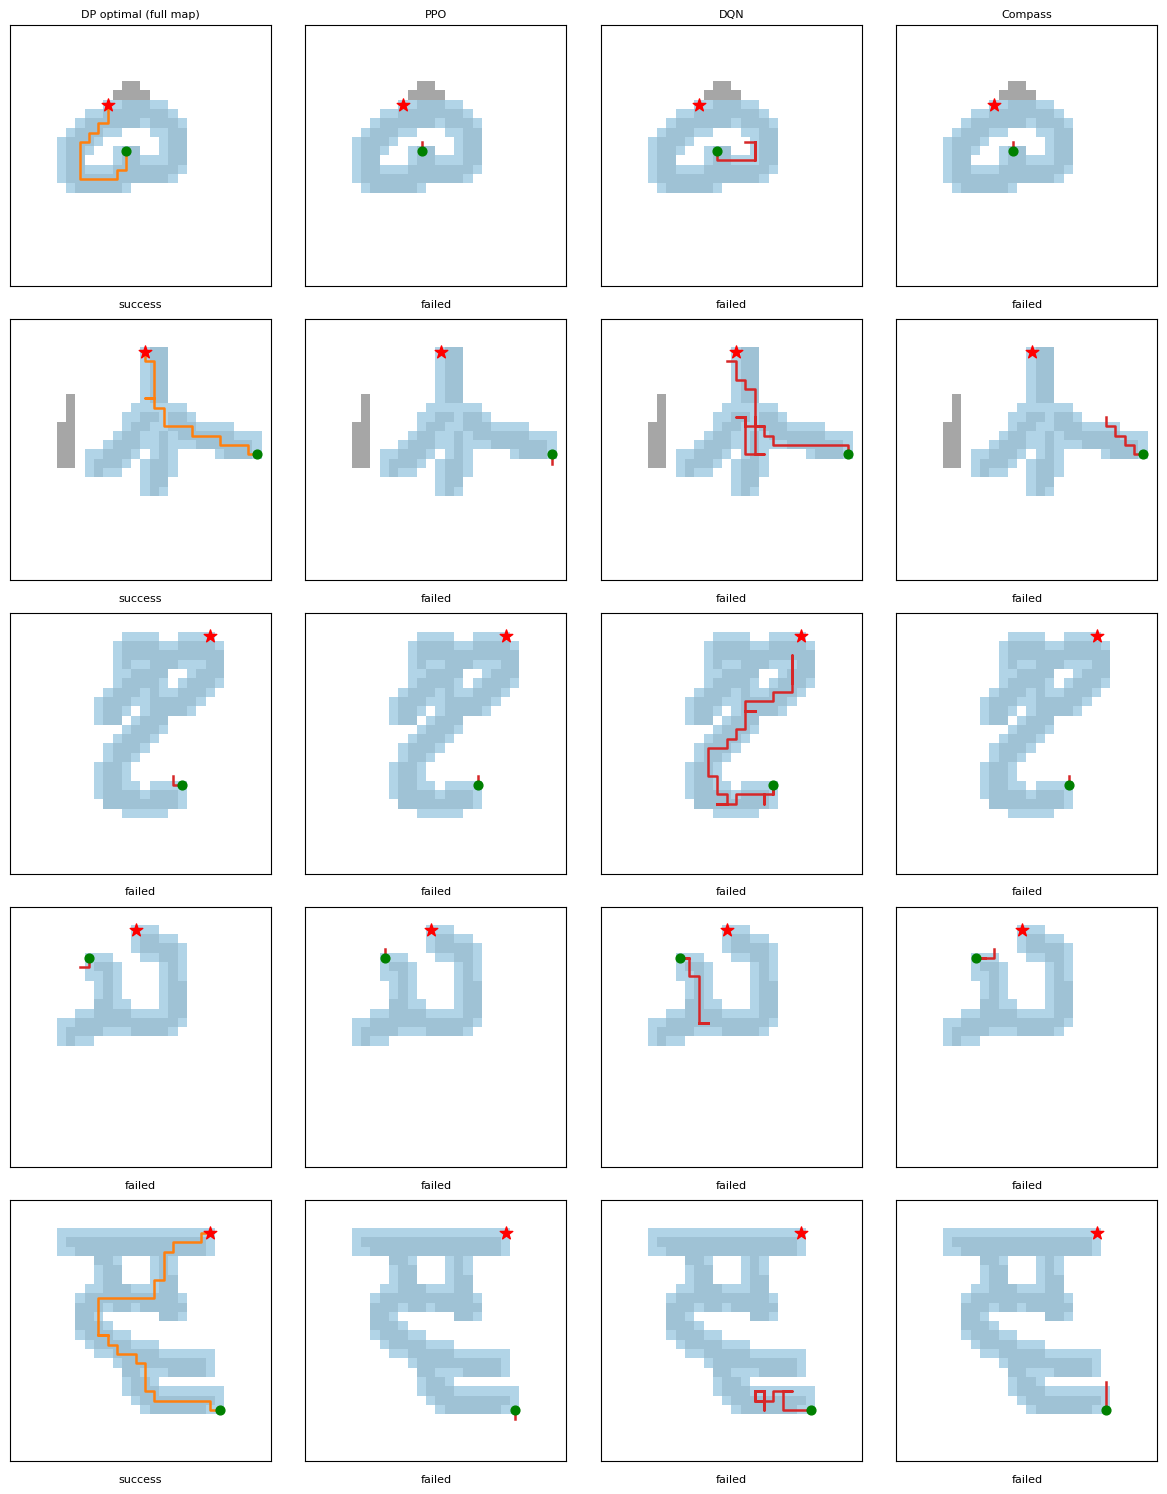

In [23]:
# [torch] traced paths on unseen characters
def record(policy_fn, tasks, ids, seed):
    env = VecGlyphEnv(tasks, len(ids), ENV, seed, autoreset=False, task_ids=ids)
    paths = [[tuple(p)] for p in env.pos]
    while env.active.any():
        before = env.active.copy()
        env.step(policy_fn(env))
        for i in np.flatnonzero(before):
            paths[i].append(tuple(env.pos[i]))
    ok = {s["task"]: s["success"] for s in env.pop_stats()}
    return [np.array(p) for p in paths], [ok[int(t)] for t in ids]

show_ids = np.arange(5)
show = {"DP optimal (full map)": dp_test, "PPO": LEARNED["PPO"], "DQN": LEARNED["DQN"], "Compass": compass_policy}
fig, axes = plt.subplots(len(show_ids), len(show), figsize=(3 * len(show), 3 * len(show_ids)))
for c, (name, pol) in enumerate(show.items()):
    paths, ok = record(pol, test_tasks, show_ids, seed=5)
    for r, (p, s) in enumerate(zip(paths, ok)):
        ax = axes[r, c]
        show_task(ax, test_tasks[show_ids[r]], name if r == 0 else None)
        ax.plot(p[:, 1], p[:, 0], c="tab:orange" if s else "tab:red", lw=1.8)
        ax.text(0.5, -0.08, "success" if s else "failed", transform=ax.transAxes, ha="center", fontsize=8)
plt.tight_layout(); plt.savefig(f"{OUT}/traces_unseen.png", dpi=150, bbox_inches="tight"); plt.show()

In [24]:
# [torch] plain-language summary generated from the numbers above
u = res[res.split == "unseen"].set_index("method")
s = res[res.split == "seen"].set_index("method")
print("Unseen alphabets, greedy success:")
for m in order:
    print(f"  {m:32s} {u.loc[m, 'success']:5.1f}%   (seen: {s.loc[m, 'success']:5.1f}%)")
best = max(LEARNED, key=lambda m: u.loc[m, "success"])
print(f"\nBest RL learner on unseen alphabets: {best}. The gap to 'DP optimal (full map)' is the price of seeing only an 11x11 window.")
print("One seed per deep method: treat differences of a few points as noise until repeated with more seeds.")
if FAST_DEV_RUN:
    print("FAST_DEV_RUN is on: budgets are tiny and these numbers say nothing about the methods.")

Unseen alphabets, greedy success:
  Random                             0.0%   (seen:   0.0%)
  Compass                            4.4%   (seen:   2.6%)
  Shortest path (full map)          75.4%   (seen:  69.6%)
  DP optimal (full map)             95.0%   (seen:  94.0%)
  Behaviour cloning (DP teacher)    65.8%   (seen:  81.4%)
  DQN                                4.6%   (seen:   6.6%)
  REINFORCE + baseline               0.0%   (seen:   0.0%)
  A2C                                0.0%   (seen:   0.0%)
  PPO                                0.0%   (seen:   0.0%)

Best RL learner on unseen alphabets: Behaviour cloning (DP teacher). The gap to 'DP optimal (full map)' is the price of seeing only an 11x11 window.
One seed per deep method: treat differences of a few points as noise until repeated with more seeds.


## 8. Reading the results honestly
* **References frame everything.** Compass shows that heading for the goal is not enough; the two full-map planners show the ceiling. DP optimal beating shortest path on the same maps is the cleanest result here: planning for uncertainty matters more than path length.
* **Behaviour cloning is not RL.** It copies a planner that sees the whole map. Its score shows how much a policy over this observation *can* achieve, which tells you whether a weak RL result is an optimization problem or an observation problem.
* **Seen versus unseen** measures generalization across writing systems. A small gap means the agents learned to follow strokes, not to memorize glyphs.
* **Training curves include exploration.** DQN's curve is measured with epsilon-greedy actions, so it understates the greedy policy evaluated in the table.
* **Single seed.** Deep RL results vary between seeds. Before claiming one method beats another, repeat with at least three seeds and report the spread.

## 9. Where this goes next
1. **Drawing, not just tracing:** let the agent put ink down and reward similarity to a target glyph, so the policy writes a character stroke by stroke. Few-shot generation (my MS thesis) could then be conditioned on a handful of support glyphs, as in my SCACM proposal.
2. **Model-based deep RL:** learn the slip dynamics and plan with a probabilistic ensemble, as in PETS from the final course week, and compare its sample efficiency with PPO.
3. **Real handwriting:** use Omniglot's recorded pen trajectories as demonstrations and compare behaviour cloning, RL, and RL fine-tuning of a cloned policy.

### References
* Sutton and Barto. Reinforcement Learning: An Introduction, 2nd edition. 2018.
* Lake, Salakhutdinov and Tenenbaum. Human-level concept learning through probabilistic program induction. Science 2015.
* Mnih et al. Human-level control through deep reinforcement learning. Nature 2015.
* Williams. Simple statistical gradient-following algorithms for connectionist reinforcement learning. Machine Learning 1992.
* Schulman et al. Proximal Policy Optimization Algorithms. 2017. Schulman et al. High-Dimensional Continuous Control Using Generalized Advantage Estimation. ICLR 2016.
* Chua et al. Deep Reinforcement Learning in a Handful of Trials using Probabilistic Dynamics Models (PETS). NeurIPS 2018.
* Anderson et al. On Evaluation of Embodied Navigation Agents (SPL). 2018.
* Ganin et al. Synthesizing Programs for Images using Reinforced Adversarial Learning (SPIRAL). ICML 2018.
* Huang, Heng and Zhou. Learning to Paint with Model-based Deep Reinforcement Learning. ICCV 2019.